### Data Preparation, Exploratory Data Analysis (EDA), Feature Importance, and Model Selection steps.

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

plt.style.use("seaborn-v0_8-poster")
%matplotlib inline

1. Data Loading, Cleaning, Missing Values, Stats, Ranges

In [3]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# Check for missing values
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [8]:
# Check for data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [78]:
categorical_features = ['sex', 'smoker', 'region']
numerical_features = ['age', 'bmi', 'children']

In [9]:
# Look at the min, max, and ranges of numerical values
df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


2. Exploratory Data Analysis (EDA) - target variable, numerical/categorical features, and feature importance.

The target variable (`charges`) represents the medical costs - its distribution has a long tail with a few observations of high charges:

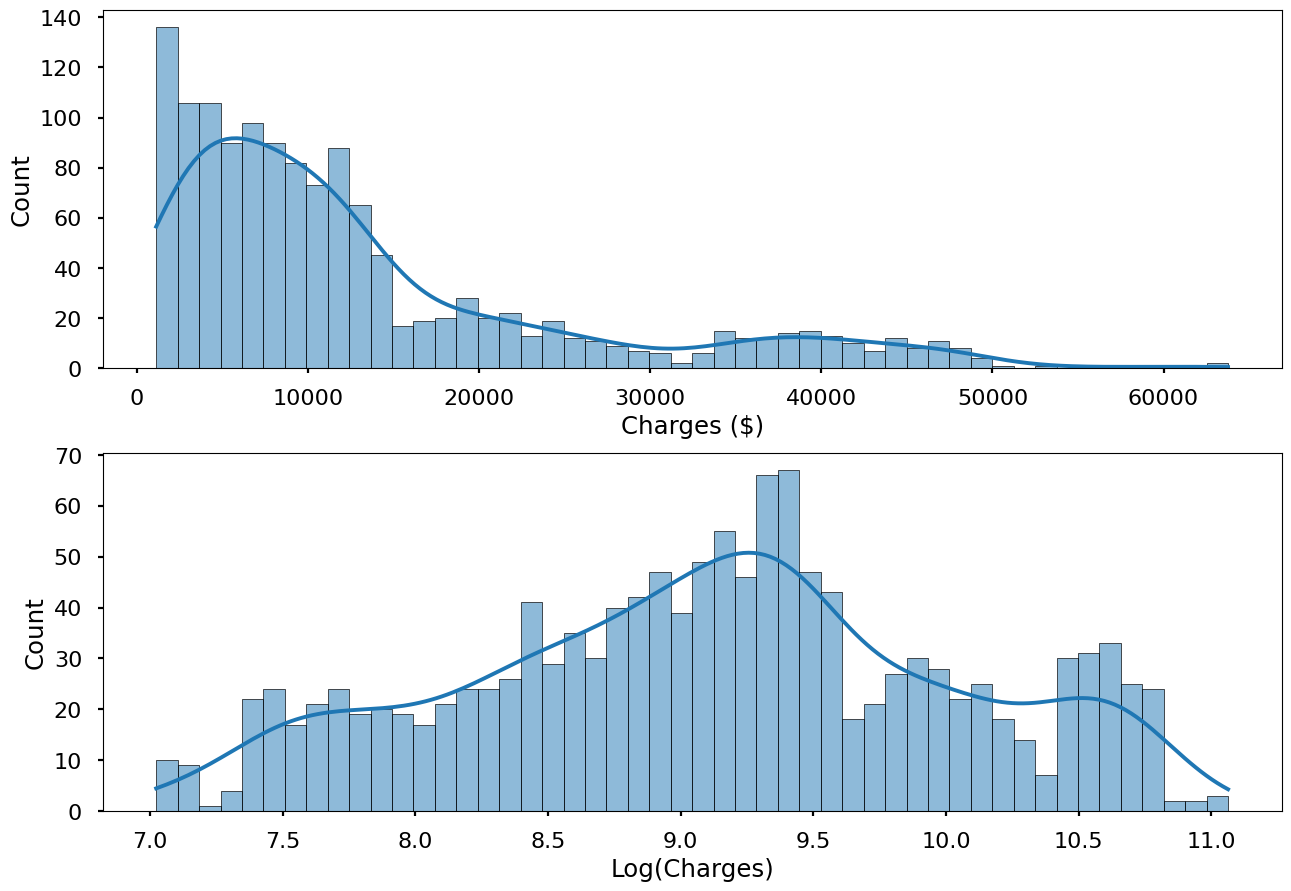

In [ ]:
fig = plt.figure(dpi=100, layout='constrained')

# Distribution
ax  = fig.add_subplot(2,1,1)
ax  = sns.histplot(df['charges'], bins=50, kde=True, ax=ax)
_   = ax.set_xlabel('Charges ($)')

# Log Transformation
ax  = fig.add_subplot(2,1,2)
ax  = sns.histplot(np.log1p(df['charges']), bins=50, kde=True, ax=ax)
_   = ax.set_xlabel('Log(Charges)')

Feature Analysis: Categorical variables:
- female and male share its average but male tend to produce more extreme costs
- moking shifts the charges to high costs
- eastern regions produce extreme costs

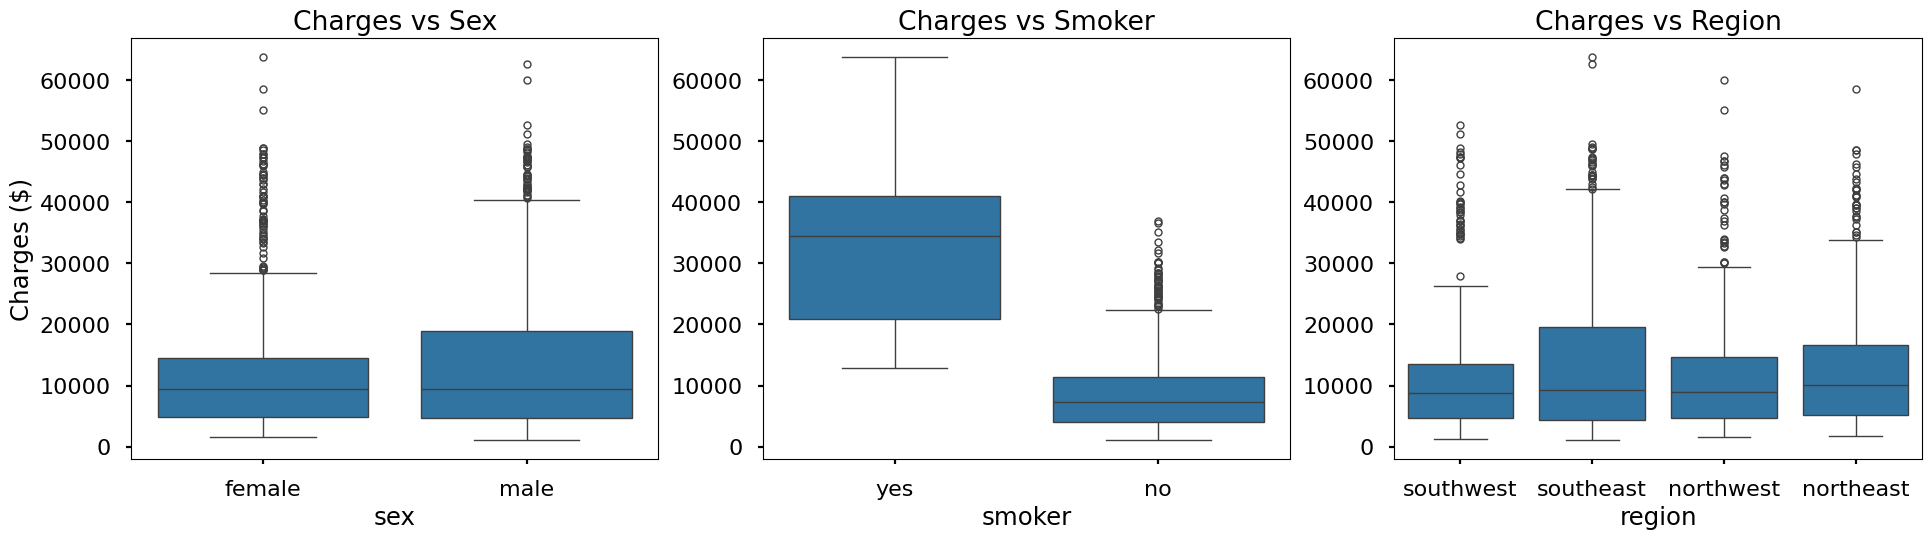

In [ ]:
fig, axes = plt.subplots(1, 3, layout='constrained')
fig.set_figwidth(fig.get_figwidth()*1.5)
fig.set_figheight(fig.get_figheight()*0.6)

for i, col in enumerate(categorical_features):
    axes[i] = sns.boxplot(x=df[col], y=df['charges'], ax=axes[i], fliersize=5)
    axes[i].set_title(f'Charges vs {col.capitalize()}')
    if i == 0:
        _ = axes[i].set_ylabel('Charges ($)')
    else:
        _ = axes[i].set_ylabel('')

Feature Analysis: Numerical variables:
- age increases charges linearly
- clear nonlinear behabiour between charges and bmi/smoking
  - charges and bmi are about uncorrelated for non-smoker
  - charges increase vastly with bmi for smoker
- charges and children are roughly uncorrelated

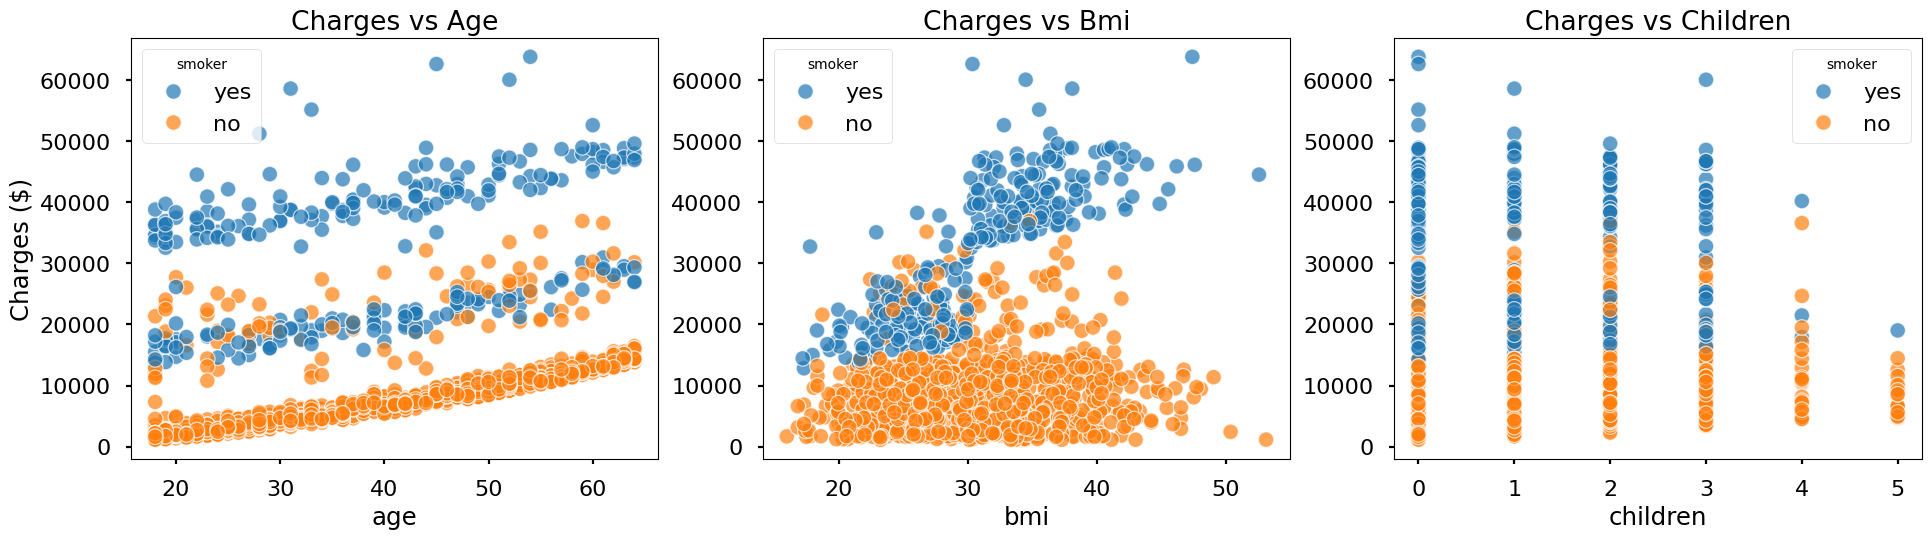

In [ ]:
fig, axes = plt.subplots(1, 3, layout='constrained')
fig.set_figwidth(fig.get_figwidth()*1.5)
fig.set_figheight(fig.get_figheight()*0.6)

for i, col in enumerate(numerical_features):
    axes[i] = sns.scatterplot(data=df, x=col, y='charges', ax=axes[i], hue='smoker', alpha=0.7)
    axes[i].set_title(f'Charges vs {col.capitalize()}')
    if i == 0:
        _ = axes[i].set_ylabel('Charges ($)')
    else:
        _ = axes[i].set_ylabel('')

3. Given the info about smoking-status we stratify our split

In [103]:
# 1. First split: Pull out the 20% test set, stratifying on 'smoker'
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1, stratify=df['smoker']
)

# 2. Second split: Split the remaining 80% into train (60%) and validation (20%), stratifying again
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1, stratify=df_full_train['smoker']
)

# 3. Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# 4. Extract and transform target variables
y_train = np.log1p(df_train.charges.values)
y_val = np.log1p(df_val.charges.values)
y_test = np.log1p(df_test.charges.values)

4. Feature Importance Analysis - For numerical features, we can use correlation. For categorical features, we can use Mutual Information.

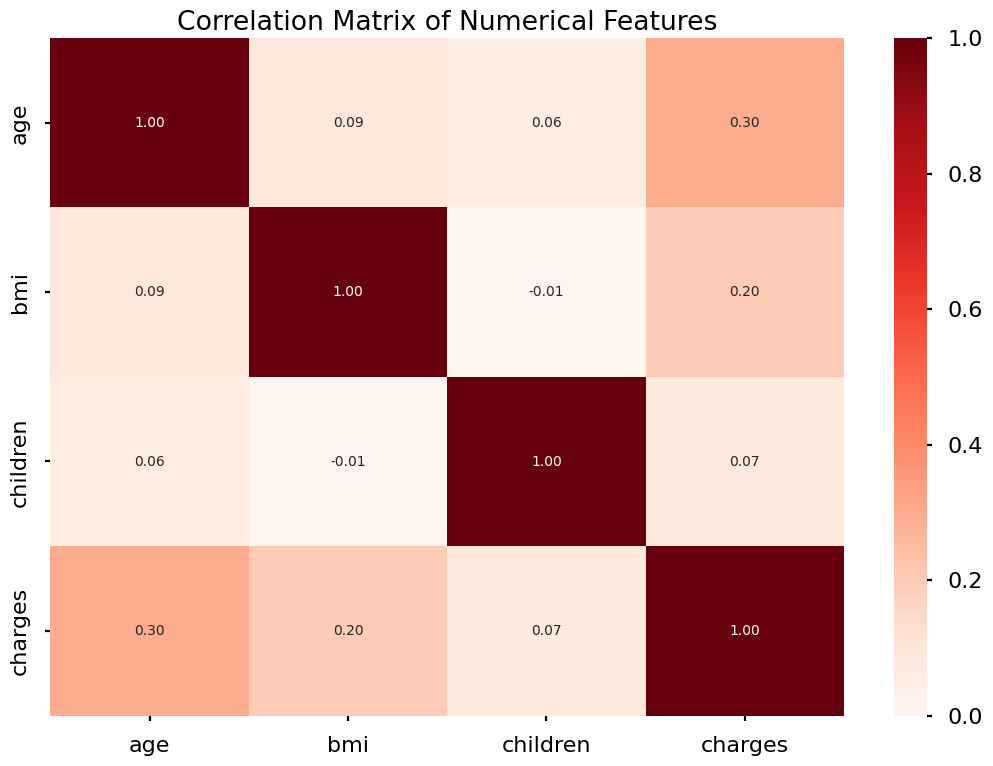

In [104]:
numerical_columns = numerical_features + ['charges']
correlation_matrix = df_train[numerical_columns].corr()

fig = plt.figure(dpi=100)
ax  = fig.add_subplot()
ax  = sns.heatmap(correlation_matrix, annot=True, cmap='Reds', fmt=".2f", vmin=0, vmax=1)
_   = ax.set_title('Correlation Matrix of Numerical Features')

In [105]:
cat_df = df_train[categorical_features].apply(lambda x: x.astype('category').cat.codes)

def calculate_mi(series):
    return mutual_info_regression(series.values.reshape(-1, 1), df_train['charges'])[0]

mi_scores = cat_df.apply(calculate_mi)
mi_scores.sort_values(ascending=False)

smoker    0.380695
sex       0.098889
region    0.053352
dtype: float64

5. Model 1: Ridge and Lasso Regression (Linear Model)

In [ ]:
# Convert dataframes to dictionaries for DictVectorizer
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

# Initialize and fit DictVectorizer
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Check the generated features ('smoker', 'sex', and 'region' are One-Hot Encoded)
print(dv.get_feature_names_out())

['age' 'bmi' 'charges' 'children' 'region=northeast' 'region=northwest'
 'region=southeast' 'region=southwest' 'sex=female' 'sex=male' 'smoker=no'
 'smoker=yes']


In [ ]:
# Testing different regularization strengths (alpha)
alphas = [0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

# Ridge Regression
print("Ridge Regression:")
for a in alphas:
    # 1. Train the model
    model_ridge = Ridge(alpha=a, random_state=1)
    model_ridge.fit(X_train, y_train)
    
    # 2. Make predictions on the validation set
    y_pred_ridge = model_ridge.predict(X_val)
    
    # 3. Calculate RMSE (we use expm1 to convert predictions back from Log space to Dollars)
    rmse_ridge = np.sqrt(mean_squared_error(np.expm1(y_val), np.expm1(y_pred_ridge)))
    
    print(f'alpha = {a:<5} | Validation RMSE: ${rmse_ridge:,.2f}')

# Lasso Regression
print("\nLasso Regression:")
for a in alphas[1:]:
    # Train Lasso
    model_lasso = Lasso(alpha=a, random_state=1)
    model_lasso.fit(X_train, y_train)
    
    # Predict and calculate exact dollar RMSE
    y_pred_lasso = model_lasso.predict(X_val)
    rmse_lasso = np.sqrt(mean_squared_error(np.expm1(y_val), np.expm1(y_pred_lasso)))
    
    print(f'Lasso alpha = {a:<5} | Validation RMSE: ${rmse_lasso:,.2f}')

Ridge Regression:
alpha = 0     | Validation RMSE: $10,539.90
alpha = 0.001 | Validation RMSE: $10,862.67
alpha = 0.01  | Validation RMSE: $10,862.78
alpha = 0.1   | Validation RMSE: $10,863.88
alpha = 1.0   | Validation RMSE: $10,874.70
alpha = 10.0  | Validation RMSE: $10,974.66
alpha = 100.0 | Validation RMSE: $11,538.55

Lasso Regression:
Lasso alpha = 0.001 | Validation RMSE: $11,002.39
Lasso alpha = 0.01  | Validation RMSE: $12,274.51
Lasso alpha = 0.1   | Validation RMSE: $13,406.52
Lasso alpha = 1.0   | Validation RMSE: $13,201.15
Lasso alpha = 10.0  | Validation RMSE: $13,994.39
Lasso alpha = 100.0 | Validation RMSE: $13,459.48


6. Random Forest Regression (Nonlinear Model)

In [130]:
# Define the parameter grids
depths = [5, 10, 15, 20, None]
estimators = [10, 50, 100, 200, 250]

# Iterate through all combinations
for d in depths:
    for n in estimators:
        # Train the model with the current parameters
        rf = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=1)
        rf.fit(X_train, y_train)
        
        # Predict and calculate error in exact dollars
        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(np.expm1(y_val), np.expm1(y_pred)))
        
        print(f'max_depth={str(d):<4} | n_estimators={n:<3} | Validation RMSE: ${rmse:,.2f}')

max_depth=5    | n_estimators=10  | Validation RMSE: $535.27
max_depth=5    | n_estimators=50  | Validation RMSE: $527.30
max_depth=5    | n_estimators=100 | Validation RMSE: $520.82
max_depth=5    | n_estimators=200 | Validation RMSE: $523.49
max_depth=5    | n_estimators=250 | Validation RMSE: $531.15
max_depth=10   | n_estimators=10  | Validation RMSE: $192.47
max_depth=10   | n_estimators=50  | Validation RMSE: $183.61
max_depth=10   | n_estimators=100 | Validation RMSE: $184.58
max_depth=10   | n_estimators=200 | Validation RMSE: $178.86
max_depth=10   | n_estimators=250 | Validation RMSE: $183.34
max_depth=15   | n_estimators=10  | Validation RMSE: $179.02
max_depth=15   | n_estimators=50  | Validation RMSE: $202.28
max_depth=15   | n_estimators=100 | Validation RMSE: $201.40
max_depth=15   | n_estimators=200 | Validation RMSE: $197.49
max_depth=15   | n_estimators=250 | Validation RMSE: $201.77
max_depth=20   | n_estimators=10  | Validation RMSE: $179.02
max_depth=20   | n_estim